# 04 · EMT-TF expression — Ji et al. 2020

Unconditional final step (outside the gate chain). Score a mesenchymal-TF panel (Snail/Zeb/Twist **plus** FOXC/PRRX — the Kürten lesson), detection-gated at a 3% floor for sparse 10x, and overlay the strongest early (root) and late (terminus) expressers on the manifold.

Numbered **04** because the analysis is non-branching (Gate 3 NA): the branching-only `04_correlation` / `05_modules` notebooks are not produced (§6).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
os.makedirs(pth_fig, exist_ok=True)
# signatures.h5ad carries the processed matrix plus the oriented linear layout used by every panel
adata = sc.read_h5ad(os.path.join(pth_out,'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 10531 | pseudotime 0.0 -> 12.64


### Panel scoring — detection-gated (3% floor)

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn,x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early>df.mean_late,'EARLY(root)','LATE(terminus)')
df = df.sort_values('rho_vs_t'); print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')
print('Canonical SNAI1/ZEB1/TWIST sit near the 10x dropout floor; SNAI2/SLUG is the'
      ' terminal expresser (a neural-crest EMT-TF, coherent with the Crest-high TSK leading edge).')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.047       0.019      0.017    -0.034    EARLY(root)
 SNAI1      0.028       0.012      0.008    -0.023    EARLY(root)
  ZEB2      0.026       0.009      0.011    -0.006 LATE(terminus)
 PRRX2      0.097       0.041      0.047    -0.006 LATE(terminus)
TWIST1      0.002       0.001      0.000     0.002    EARLY(root)
TWIST2      0.001       0.000      0.000     0.005 LATE(terminus)
 FOXC2      0.000       0.000      0.000     0.010 LATE(terminus)
 PRRX1      0.004       0.001      0.002     0.017 LATE(terminus)
  ZEB1      0.008       0.002      0.005     0.023 LATE(terminus)
 SNAI2      0.552       0.226      0.576     0.312 LATE(terminus)

derived pair: FOXC1 (early/root) <-> SNAI2 (late/terminus)
Canonical SNAI1/ZEB1/TWIST sit near the 10x dropout floor; SNAI2/SLUG is the terminal expresser (a neural-crest EMT-TF, coherent with the Crest-high TSK leading edge).


### `expression.pdf` — categorical overlay of thresholded expressers

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.542, 'SNAI2': 0.981} | cells shown: {'FOXC1': 125, 'SNAI2': 1452}
shown-cell pseudotime separation (FOXC1 vs SNAI2) = 0.22
saved expression.pdf


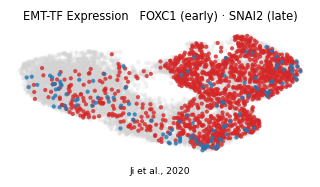

In [4]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],3) for g in [early_tf,late_tf]},
      '| cells shown:', {g:int(sel[g].sum()) for g in [early_tf,late_tf]})
order = sorted([early_tf, late_tf], key=lambda g:-int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')